# 04. Descripteurs et classification (phase 4)

Étiquettes : un candidat est positif si son centre est dans le rayon d'un nodule annoté. Découpage par patient : `dev` (15 patients) pour l'entraînement et la validation croisée groupée, `test` (10 patients) pour l'évaluation finale.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
pd.set_option("display.width", 200)
feats = pd.read_csv(RESULTS / 'features.csv')
print(feats.groupby('split').label.agg(candidats='size', positifs='sum'))
print(f'part de positifs : {100*feats.label.mean():.2f} %')
display(feats.head())

       candidats  positifs
split                     
dev         3256        22
test        2228        11
part de positifs : 0.60 %


,seriesuid,split,candidate_id,z_voxel,y_voxel,x_voxel,volume_mm3,diameter_mm,max_radius_mm,skeleton_length_mm,...,skeleton_ratio,border_dist_mm,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation,label,world_x,world_y,world_z
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896...,dev,1,175.944824,184.961640,155.023121,1903.0,15.374939,6.082763,1.0,...,0.065041,7.0,2.052419,0.724159,0.291011,0.952673,0,-27.476879,-5.038360,-137.805176
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896...,dev,2,142.138561,203.920401,241.853184,1696.0,14.795935,6.000000,2.0,...,0.135172,8.0,1.952117,0.702925,0.253414,0.952583,0,59.353184,13.920401,-171.611439
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896...,dev,3,210.361398,148.003971,205.640985,1259.0,13.397046,6.000000,3.0,...,0.223930,6.0,1.199093,0.773255,0.286680,0.967263,0,23.140985,-41.996029,-103.388602
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896...,dev,4,210.300100,153.959123,196.684945,1003.0,12.419404,6.000000,1.0,...,0.080519,6.0,1.089214,0.767744,0.224028,0.974489,0,14.184945,-36.040877,-103.449900
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896...,dev,5,210.248120,156.156015,203.308271,532.0,10.053200,6.000000,2.0,...,0.198942,6.0,1.158770,0.764530,0.234879,0.969574,0,20.808271,-33.843985,-103.501880


In [2]:
from src.features import FEATURE_COLUMNS
display(feats.groupby('label')[FEATURE_COLUMNS].median().T.round(2))

label,0,1
volume_mm3,38.00,63.00
diameter_mm,4.17,4.94
sphericity,0.54,0.75
solidity,0.62,1.00
elongation,4.66,2.06
mean_hu,-58.84,-116.46
std_hu,119.59,108.72
grad_mean,794.88,760.72
glcm_contrast,1.55,1.38
glcm_homogeneity,0.73,0.76


## Scénario B : importance des descripteurs (Random Forest)

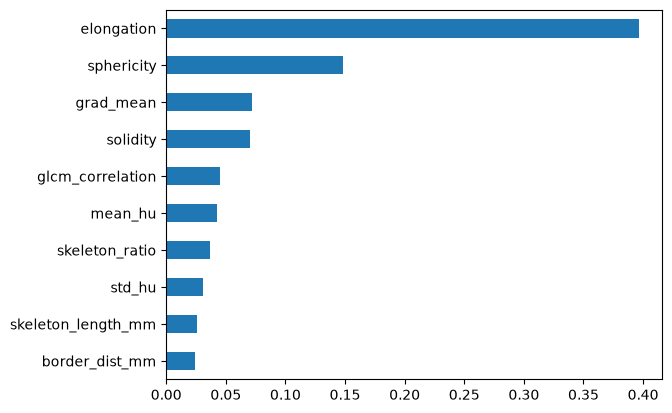

In [3]:
imp = pd.read_csv(RESULTS / 'importance_descripteurs.csv', index_col=0)
imp.head(10).plot.barh(legend=False).invert_yaxis(); plt.show()

## Scénario C : courbes d'entraînement du CNN 3D

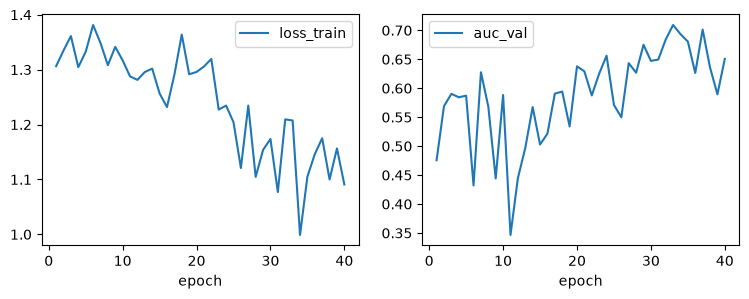

In [4]:
c = pd.read_csv(RESULTS / 'courbes_cnn.csv')
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
c.plot(x='epoch', y='loss_train', ax=ax[0]); c.plot(x='epoch', y='auc_val', ax=ax[1]); plt.show()

In [5]:
for key in 'ABC':
    p = pd.read_csv(RESULTS / f'predictions_{key}.csv')
    print(key, len(p), 'prédictions sur le test, temps', round(p.temps_s.iloc[0], 1), 's')

A 2228 prédictions sur le test, temps 0.1 s
B 2228 prédictions sur le test, temps 0.6 s
C 2228 prédictions sur le test, temps 869.4 s
